# The Green Speed Run: tiled Cholesky on the GPU
**Team Dos-Kallas · #1013** · Al-Khawarizmi Tour · Online Hackathon HPC & AI · Week-5 team challenge

Our tiled Cholesky factorization from HW3, moved to an NVIDIA GPU with CUDA.jl, in FP32 and FP64, benchmarked for N = 1000, 1500, …, 7000.

The code is in `src/cholesky_gpu.jl`. This notebook loads it, checks correctness, tunes the tile size and draws the performance graph. The Slurm job on the cluster runs the same file with `julia --project src/cholesky_gpu.jl`.

## 0 · Setup
Kernel: **Julia (auto threads) 1.13**. Run from the `Assignment5/` folder: `Project.toml` there pins CUDA.jl.

In [1]:
using Pkg
Pkg.activate(".")
include("src/cholesky_gpu.jl")
using Plots

println(gpu_summary())
PEAKS = gpu_peaks()
@printf("theoretical peak | FP32 %.0f GFlop/s | FP64 %.0f GFlop/s\n", PEAKS.fp32, PEAKS.fp64)

  Activating project at `c:\Users\youss\Projects\python\AKT_HaT\Assignment5`


NVIDIA GeForce RTX 3060 Laptop GPU | compute capability 8.6.0 | 30 SMs | 6.0 GiB | driver 13.3.0 | CUDA runtime 13.0.0
theoretical peak | FP32 16128 GFlop/s | FP64 252 GFlop/s


## 1 · The algorithm
Same blocked equations as HW3. With tiles of size nb, at step $k$:

$$
\begin{bmatrix}A_{kk}&\\A_{\text{rest},k}&A_{\text{rest}}\end{bmatrix}
=
\begin{bmatrix}L_{kk}&\\L_{\text{rest},k}&L_{\text{rest}}\end{bmatrix}
\begin{bmatrix}L_{kk}^\top&L_{\text{rest},k}^\top\\&L_{\text{rest}}^\top\end{bmatrix}
$$

| Step | Operation | GPU library call |
|---|---|---|
| POTRF | $L_{kk}=\text{chol}(A_{kk})$ | `CUSOLVER.potrf!` |
| TRSM | $L_{ik}=A_{ik}L_{kk}^{-\top}$ for every tile below | `CUBLAS.trsm!` |
| SYRK / GEMM | $A_{ij}\leftarrow A_{ij}-L_{ik}L_{jk}^\top$ for every remaining tile | `CUBLAS.syrk!` / `CUBLAS.gemm!` |

Two variants of `cholesky_tiled_gpu!`:
* **`:tile`** follows the HW3 table literally: one library call per tile.
* **`:panel`** does the same arithmetic with all tiles of a step merged: one TRSM on the whole panel $\begin{bmatrix}A_{k+1,k}\\ \vdots\\ A_{p,k}\end{bmatrix}$ and one SYRK on the whole trailing matrix, because block $(i,j)$ of $L_{\text{rest},k}L_{\text{rest},k}^\top$ is exactly $L_{ik}L_{jk}^\top$.

Inside each call the GPU spreads the work over thousands of threads; the calls of one step run in order on the same stream, so no explicit barrier is needed. `cholesky_cusolver!` (one `potrf!` on the whole matrix) is the vendor reference, like LAPACK in HW3.

## 2 · Correctness
Acceptance test from HW3: backward error $\eta \le 10\,N\,\varepsilon$, computed in Float64. Sizes 203 (not a multiple of any tile size) and 1000, both precisions, every variant, plus the difference to the CPU (LAPACK) factor.

In [2]:
correctness = NamedTuple[]
for T in (Float32, Float64), n in (203, 1000)
    A0 = generate_spd(n; T = T)
    b  = A0 * generate_solution(n; T = T)
    L_cpu = cholesky(Symmetric(Array(A0), :L)).L
    for (name, f!) in (("tiled_tile nb=64",   A -> cholesky_tiled_gpu!(A, 64; variant = :tile)),
                       ("tiled_panel nb=64",  A -> cholesky_tiled_gpu!(A, 64; variant = :panel)),
                       ("tiled_panel nb=512", A -> cholesky_tiled_gpu!(A, 512; variant = :panel)),
                       ("cusolver",           cholesky_cusolver!))
        F = f!(copy(A0))
        η = backward_error(A0, chol_solve!(F, copy(b)), b)
        push!(correctness, (precision = string(T), n = n, impl = name, η = η, limit = 10n * eps(T),
                            diff_cpu = maximum(abs, tril(Array(F)) - L_cpu) / maximum(abs, L_cpu)))
    end
end

@printf("%-8s %5s  %-19s %10s %10s %10s\n", "type", "n", "impl", "η", "10nε", "vs CPU")
for r in correctness
    @printf("%-8s %5d  %-19s %10.2e %10.2e %10.2e  %s\n", r.precision, r.n, r.impl, r.η, r.limit, r.diff_cpu,
            r.η <= r.limit ? "✅" : "❌")
end

posdef_rejected = try
    cholesky_tiled_gpu!(CuArray(Float64[1 2; 2 1]), 1); false
catch err
    err isa PosDefException
end
println("indefinite matrix rejected with PosDefException: ", posdef_rejected ? "✅" : "❌")
println("all correctness checks passed: ", all(r -> r.η <= r.limit, correctness) && posdef_rejected ? "✅" : "❌")

type         n  impl                         η       10nε     vs CPU
Float32    203  tiled_tile nb=64      1.03e-07   2.42e-04   1.73e-07  ✅
Float32    203  tiled_panel nb=64     1.19e-07   2.42e-04   1.73e-07  ✅
Float32    203  tiled_panel nb=512    1.48e-07   2.42e-04   2.09e-07  ✅
Float32    203  cusolver              1.48e-07   2.42e-04   2.09e-07  ✅
Float32   1000  tiled_tile nb=64      2.93e-07   1.19e-03   5.55e-07  ✅
Float32   1000  tiled_panel nb=64     2.65e-07   1.19e-03   5.26e-07  ✅
Float32   1000  tiled_panel nb=512    2.84e-07   1.19e-03   5.22e-07  ✅
Float32   1000  cusolver              3.64e-07   1.19e-03   6.06e-07  ✅
Float64    203  tiled_tile nb=64      2.70e-16   4.51e-13   4.27e-16  ✅
Float64    203  tiled_panel nb=64     2.70e-16   4.51e-13   4.27e-16  ✅
Float64    203  tiled_panel nb=512    2.70e-16   4.51e-13   4.27e-16  ✅
Float64    203  cusolver              2.70e-16   4.51e-13   4.27e-16  ✅
Float64   1000  tiled_tile nb=64      5.04e-16   2.22e-12   9.71e-1

## 3 · Tile size
Same granularity question as HW3 Chapter 2, at one size. Small tiles mean many small library calls; large tiles mean a long sequential POTRF on the diagonal tile at every step.


GFlop/s at N = 4000, Float32
variant       nb=64   nb=128   nb=256   nb=384   nb=512   nb=768  nb=1024  nb=1536  nb=2048
tile             32      210      751     1168     1578     1777     2341     2541     2936
panel          1273     1639     2170     2224     2420     2506     2469     2607     2861
cuSOLVER: 2728 GFlop/s

GFlop/s at N = 4000, Float64
variant       nb=64   nb=128   nb=256   nb=384   nb=512   nb=768  nb=1024  nb=1536  nb=2048
tile             15       62       87      115      104      125      128      142      161
panel           131      124      132      132      138      141      147      153      161
cuSOLVER: 187 GFlop/s


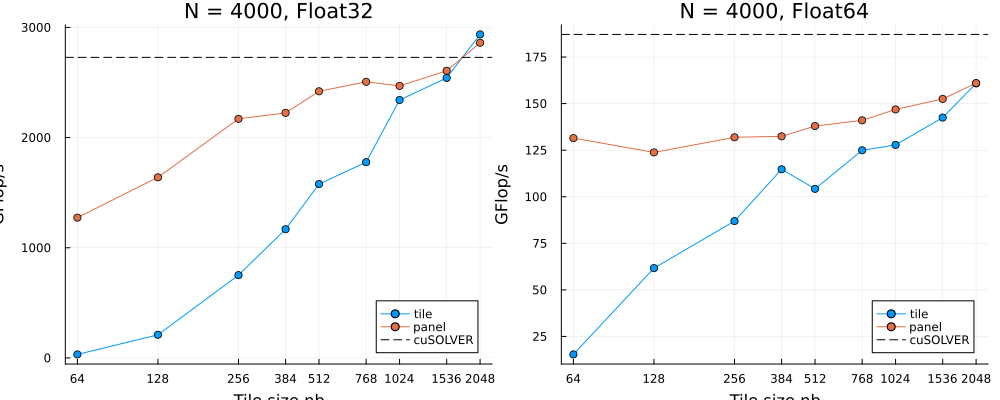

In [3]:
N_SWEEP  = 4000
NBS_SWEEP = (64, 128, 256, 384, 512, 768, 1024, 1536, 2048)

nb_sweep = NamedTuple[]
for T in (Float32, Float64)
    A0 = generate_spd(N_SWEEP; T = T)
    warmup(T)
    for variant in (:tile, :panel), nb in NBS_SWEEP
        t = bench_gpu(A -> cholesky_tiled_gpu!(A, nb; variant = variant), A0)
        push!(nb_sweep, (precision = string(T), variant = variant, nb = nb, gflops = gflops(chol_flops(N_SWEEP), t)))
    end
    t = bench_gpu(cholesky_cusolver!, A0)
    push!(nb_sweep, (precision = string(T), variant = :cusolver, nb = 0, gflops = gflops(chol_flops(N_SWEEP), t)))
end

for prec in ("Float32", "Float64")
    println("\nGFlop/s at N = $N_SWEEP, $prec")
    println(rpad("variant", 10), join([lpad("nb=$nb", 9) for nb in NBS_SWEEP]))
    for variant in (:tile, :panel)
        println(rpad(string(variant), 10),
                join([lpad(@sprintf("%.0f", only(r.gflops for r in nb_sweep if r.precision == prec && r.variant == variant && r.nb == nb)), 9)
                      for nb in NBS_SWEEP]))
    end
    @printf("cuSOLVER: %.0f GFlop/s\n", only(r.gflops for r in nb_sweep if r.precision == prec && r.variant == :cusolver))
end

panels = map(("Float32", "Float64")) do prec
    p = plot(; xscale = :log2, xticks = (collect(NBS_SWEEP), string.(NBS_SWEEP)), xlabel = "Tile size nb",
             ylabel = "GFlop/s", title = "N = $N_SWEEP, $prec", legend = :bottomright)
    for variant in (:tile, :panel)
        rr = filter(r -> r.precision == prec && r.variant == variant, nb_sweep)
        plot!(p, [r.nb for r in rr], [r.gflops for r in rr]; marker = :circle, label = string(variant))
    end
    hline!(p, [only(r.gflops for r in nb_sweep if r.precision == prec && r.variant == :cusolver)];
           ls = :dash, color = :black, label = "cuSOLVER")
    p
end
display(plot(panels...; layout = (1, 2), size = (1000, 400)))

## 4 · Benchmark: N = 1000 … 7000
On the cluster, `slurm/run_gpu.slurm` runs `julia --project src/cholesky_gpu.jl` in one of three modes (`CHOL_MODE`):

| Mode | What it runs | Output |
|---|---|---|
| `quick` | N = 1000, 2000, 3000, two tile sizes: checks the cluster setup | `results/exploration/results_gpu_team1013_quick.csv` |
| `explore` | every N, both variants, nb ∈ {256, 384, 512, 768, 1024, 1536, 2048} | `results/exploration/results_gpu_team1013_explore.csv` |
| `final` | every N, only the fastest configuration found by `explore`, plus cuSOLVER | `results/results_gpu_team1013.csv` |

Copy the cluster CSVs into those folders. This cell reads the final results if present, otherwise the exploration results, otherwise it runs the exploration on this machine into `results/exploration/results_gpu_local.csv` (set `RERUN_LOCAL = true` to measure again). Every configuration gets one untimed run, then the fastest of 3 timed runs is kept, and η is checked on every row.

In [4]:
LOCAL_CSV   = joinpath(RESULTS_DIR, "exploration", "results_gpu_local.csv")
RERUN_LOCAL = false

CLUSTER_CSVS = [CSV_FOR["final"], CSV_FOR["explore"]]
i_cluster    = findfirst(isfile, CLUSTER_CSVS)

rows, source = if i_cluster !== nothing
    read_csv(CLUSTER_CSVS[i_cluster]), CLUSTER_CSVS[i_cluster]
elseif isfile(LOCAL_CSV) && !RERUN_LOCAL
    read_csv(LOCAL_CSV), LOCAL_CSV
else
    run_benchmarks(csv = LOCAL_CSV), LOCAL_CSV
end

println("results from $source | GPU: $(first(rows).gpu) | $(length(rows)) rows | every row passed η ≤ 10Nε: ",
        all(r -> r.passed, rows) ? "✅" : "❌")

results from c:\Users\youss\Projects\python\AKT_HaT\Assignment5\results\results_gpu_team1013.csv | GPU: NVIDIA GB10 | 52 rows | every row passed η ≤ 10Nε: ✅


In [5]:
PRECS = ("Float32", "Float64")
NS    = sort(unique(r.N for r in rows))

best_tiled(prec, n) = argmax(r -> r.gflops, filter(r -> r.precision == prec && r.N == n && startswith(r.impl, "tiled"), rows))
vendor(prec, n)     = only(filter(r -> r.precision == prec && r.N == n && r.impl == "cusolver", rows))

for prec in PRECS
    println("\n$prec")
    @printf("%6s %12s %8s %6s %14s %10s %10s\n", "N", "best impl", "nb", "time", "tiled GFlop/s", "cuSOLVER", "tiled/cuS")
    for n in NS
        b, v = best_tiled(prec, n), vendor(prec, n)
        @printf("%6d %12s %8d %5.1fms %14.0f %10.0f %9.0f%%\n", n, b.impl, b.nb, 1000b.time_s, b.gflops, v.gflops, 100b.gflops / v.gflops)
    end
end


Float32
     N    best impl       nb   time  tiled GFlop/s   cuSOLVER  tiled/cuS
  1000   tiled_tile      512   2.3ms            144        211        68%
  1500  tiled_panel     1024   4.4ms            258        382        68%
  2000  tiled_panel     1536   5.5ms            481        744        65%
  2500   tiled_tile     1536   7.9ms            662       1212        55%
  3000   tiled_tile     1536   9.1ms            988       1382        71%
  3500  tiled_panel     2048  11.5ms           1248       1540        81%
  4000  tiled_panel     2048  13.4ms           1597       1657        96%
  4500  tiled_panel     1536  19.6ms           1551       1736        89%
  5000  tiled_panel     2048  23.4ms           1779       2038        87%
  5500  tiled_panel     2048  27.9ms           1988       2205        90%
  6000   tiled_tile     3072  28.9ms           2490       2355       106%
  6500  tiled_panel     3072  40.6ms           2257       2445        92%
  7000  tiled_panel     3072  

## 5 · Performance graph
Best tiled result per N (solid, every point annotated), cuSOLVER reference (dashed), theoretical peak (dotted) and our sustained peak (dash-dot) for each precision. The theoretical peak is the one of the units cuBLAS actually uses: the FP64 tensor-core peak on A100/H100, the plain FP32 peak for FP32. The y axis switches to log scale when FP32 and FP64 differ by more than 20×, as on consumer GPUs.

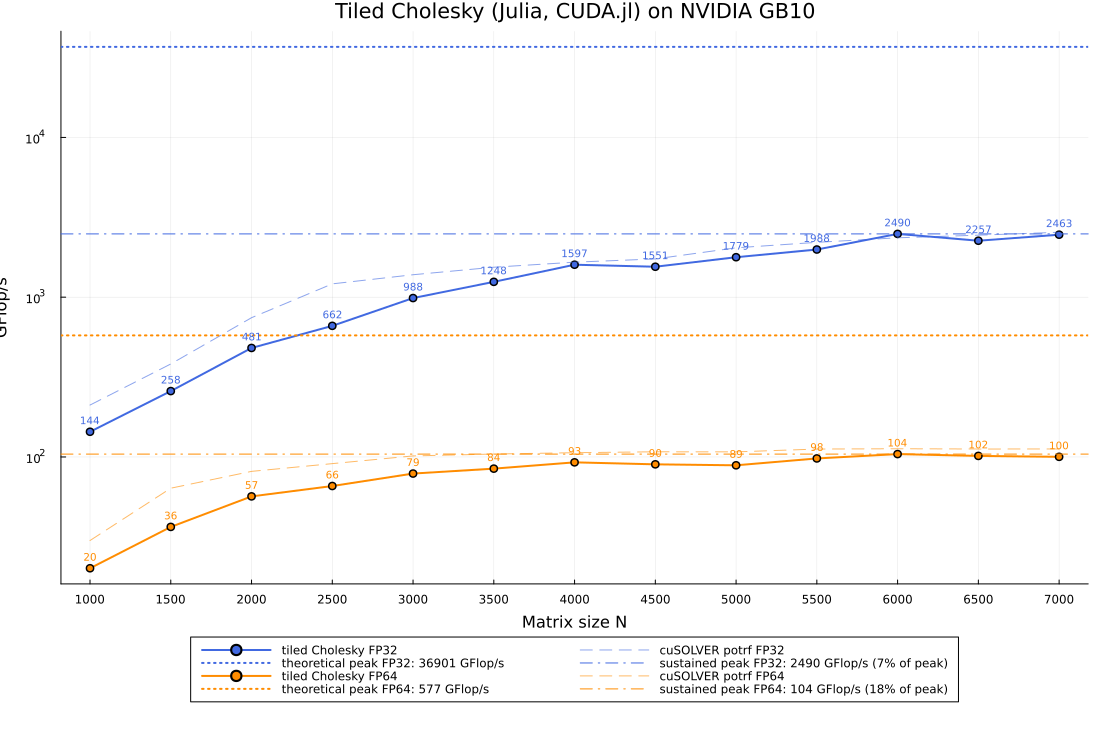

In [6]:
COLOR = Dict("Float32" => :royalblue, "Float64" => :darkorange)
SHORT = Dict("Float32" => "FP32", "Float64" => "FP64")

gpu_name   = first(rows).gpu
theory     = Dict(p => first(r.peak_gflops for r in rows if r.precision == p) for p in PRECS)
best_curve = Dict(p => [best_tiled(p, n).gflops for n in NS] for p in PRECS)
sustained  = Dict(p => maximum(best_curve[p]) for p in PRECS)
use_log    = maximum(values(theory)) / minimum(minimum.(values(best_curve))) > 20

plt = plot(; xlabel = "Matrix size N", ylabel = "GFlop/s", xticks = (NS, string.(NS)),
           yscale = use_log ? :log10 : :identity, legend = :outerbottom, legend_columns = 2,
           title = "Tiled Cholesky (Julia, CUDA.jl) on $gpu_name", size = (1100, 750))
for p in PRECS
    c = COLOR[p]
    plot!(plt, NS, best_curve[p]; marker = :circle, lw = 2, color = c, label = "tiled Cholesky $(SHORT[p])")
    plot!(plt, NS, [vendor(p, n).gflops for n in NS]; ls = :dash, color = c, alpha = 0.6, label = "cuSOLVER potrf $(SHORT[p])")
    hline!(plt, [theory[p]]; ls = :dot, lw = 2, color = c,
           label = @sprintf("theoretical peak %s: %.0f GFlop/s", SHORT[p], theory[p]))
    hline!(plt, [sustained[p]]; ls = :dashdot, color = c,
           label = @sprintf("sustained peak %s: %.0f GFlop/s (%.0f%% of peak)", SHORT[p], sustained[p], 100sustained[p] / theory[p]))
    annotate!(plt, [(n, y * (use_log ? 1.08 : 1.0) + (use_log ? 0 : 0.012maximum(values(theory))),
                     text(@sprintf("%.0f", y), 7, c, :bottom)) for (n, y) in zip(NS, best_curve[p])])
end
GRAPH = joinpath("figures", "gpu_cholesky_perf_team$(TEAM_ID).png")
savefig(plt, GRAPH)
display(plt)

In [7]:
for p in PRECS
    b = best_tiled(p, NS[argmax(best_curve[p])])
    @printf("%s: sustained %.0f GFlop/s at N = %d (%s, nb = %d) = %.1f%% of the %.0f GFlop/s theoretical peak\n",
            SHORT[p], sustained[p], b.N, b.impl, b.nb, 100sustained[p] / theory[p], theory[p])
end
println("graph saved to $GRAPH")

FP32: sustained 2490 GFlop/s at N = 6000 (tiled_tile, nb = 3072) = 6.7% of the 36901 GFlop/s theoretical peak
FP64: sustained 104 GFlop/s at N = 6000 (tiled_panel, nb = 3072) = 18.1% of the 577 GFlop/s theoretical peak
graph saved to figures\gpu_cholesky_perf_team1013.png
